# 第10章：提升在逐步改变什么

**教师参考｜全书深化稿**

## 背景与数据
四点残差例子与固定300条人工响应；不把它们写成真实房价或风洞实验。

## 本次要回答的问题
追踪两轮预测，比较学习率—轮数曲线与森林/单树。

先写下预判，再运行，最后用实际结果解释；不需要结果符合预期才算成功。

In [1]:
from pathlib import Path
import os, sys
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "experiments/common.py").exists()
             and (p / "main.tex").exists()), None)
if root is None:
    raise RuntimeError("Open this notebook inside the extracted textbook project.")
sys.path.insert(0, str(root / "experiments"))
print("Project:", root)


Project: /mnt/data/book_v3


## 可检查的完整实验代码

下方与对应`experiments`脚本一致。共享的`common.py`只提供固定数据划分、保存表图和绘图设置；模型、目标、参数及比较规则在此明确写出。阅读函数后，再运行下一单元执行实验。

In [2]:
"""Chapter 10: forward-stagewise residual fitting and validation-selected iteration."""
import numpy as np
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor,RandomForestRegressor
from sklearn.metrics import mean_squared_error
from common import *

def run():
    x=np.arange(1,5,dtype=float)[:,None];y=np.array([0.,1.,2.,4.]);pred=np.full(4,y.mean());rows=[]
    rows.append({'stage':0,'prediction':pred.tolist(),'MSE':np.mean((y-pred)**2)})
    detailed=[]
    for stage in [1,2]:
        residual=y-pred;tree=DecisionTreeRegressor(max_depth=1,random_state=42).fit(x,residual)
        correction=tree.predict(x);new=pred+.5*correction
        for i in range(4):detailed.append({'stage':stage,'x':x[i,0],'target':y[i],'old_prediction':pred[i],'residual':residual[i],'tree_prediction':correction[i],'new_prediction':new[i]})
        pred=new;rows.append({'stage':stage,'prediction':pred.tolist(),'MSE':np.mean((y-pred)**2)})
    dump('ch10_two_steps',rows);df=table('ch10_hand',detailed);show_result(df)
    tr,va,_=regression_demo();cols=['x','u'];allrows=[]
    for lr in [.03,.1,.3]:
        m=GradientBoostingRegressor(n_estimators=220,learning_rate=lr,max_depth=2,random_state=42).fit(tr[cols],tr.target)
        for k,(a,b) in enumerate(zip(m.staged_predict(tr[cols]),m.staged_predict(va[cols])),1):
            allrows.append({'learning_rate':lr,'stage':k,'train_RMSE':np.sqrt(mean_squared_error(tr.target,a)),
            'validation_RMSE':np.sqrt(mean_squared_error(va.target,b))})
    df=table('ch10_learning_curves',allrows);summary=df.loc[df.groupby('learning_rate').validation_RMSE.idxmin()];table('ch10_selected_stages',summary);show_result(summary)
    plt.figure(figsize=(6.4,4))
    for lr in [.03,.1,.3]:
        d=df[df.learning_rate==lr];plt.plot(d.stage,d.validation_RMSE,label=f'eta={lr}')
    plt.xlabel('提升轮数');plt.ylabel('验证RMSE（人工单位）');plt.legend();figure('v3_ch10_stages')
    # These are development comparisons; final test data are intentionally not touched.
    rows=[]
    for name,m in [('tree',DecisionTreeRegressor(max_depth=4,random_state=42)),('forest',RandomForestRegressor(n_estimators=200,min_samples_leaf=3,random_state=42,n_jobs=1)),('boosting',GradientBoostingRegressor(n_estimators=120,max_depth=2,learning_rate=.1,random_state=42))]:
        m.fit(tr[cols],tr.target);rows.append({'model':name,'train_RMSE':np.sqrt(mean_squared_error(tr.target,m.predict(tr[cols]))),'validation_RMSE':np.sqrt(mean_squared_error(va.target,m.predict(va[cols])))})
    table('ch10_comparison',rows)

In [3]:
result = run()
if result is not None:
    print(result)

 stage   x  target  old_prediction  residual  tree_prediction  new_prediction
     1 1.0     0.0           1.750    -1.750           -0.750          1.3750
     1 2.0     1.0           1.750    -0.750           -0.750          1.3750
     1 3.0     2.0           1.750     0.250           -0.750          1.3750
     1 4.0     4.0           1.750     2.250            2.250          2.8750
     2 1.0     0.0           1.375    -1.375           -0.875          0.9375
     2 2.0     1.0           1.375    -0.375           -0.875          0.9375
     2 3.0     2.0           1.375     0.625            0.875          1.8125
     2 4.0     4.0           2.875     1.125            0.875          3.3125


 learning_rate  stage  train_RMSE  validation_RMSE
          0.03    218    0.236509         0.332250
          0.10    116    0.193094         0.313363
          0.30     60    0.162358         0.311211


## 检查结果文件与图

下面显示该实验保存的图；所有坐标、样本与数值条件应与正文一致。数据表保存在`results/`。修改代码后，请另存结果或注明变化，不把新配置的输出与正文旧数值混用。

v3_ch10_stages.png


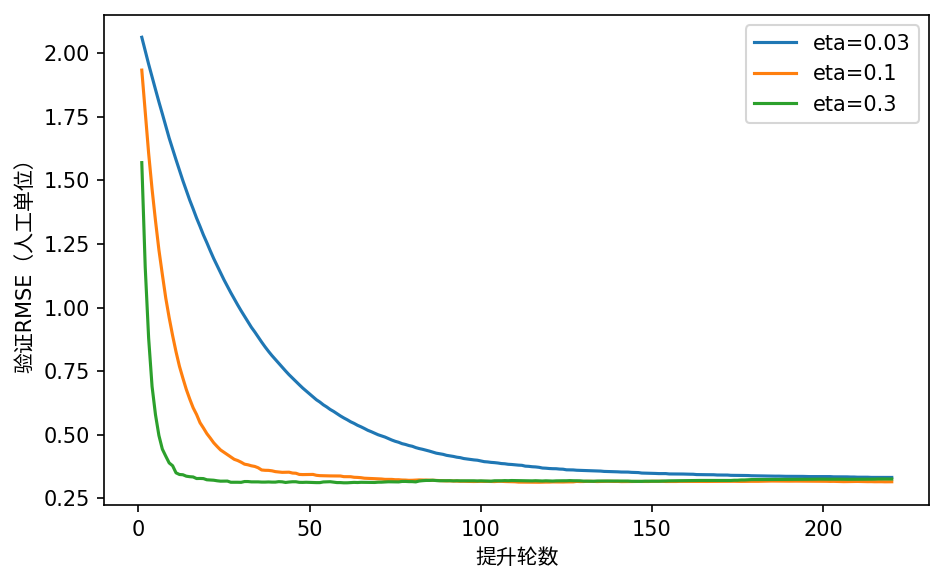

In [4]:
from IPython.display import display, Image
files = sorted((root / "figures").glob("v3_ch10_*.png"))
for path in files:
    print(path.name)
    display(Image(filename=str(path), width=720))
if not files:
    print("This experiment uses tables rather than a new figure.")

## 教师解释与核对

平方损失的残差拟合是负梯度的特例；选择最低验证轮数已属于模型选择。

完整手算解答见`teacher_manual.pdf`。如果结果与这里的参考不同，先检查数据版本、划分、软件环境、目标归一化和随机状态，不要求学生人为调成相同分数。

**评分顺序：**问题与字段角色、数据划分、算法机制、实际结果分析、证据边界。代码能运行但无法说明一项输出的含义，不算完成理解目标。